# RSNA Pneumonia: Stage 2 Verifier (final model)
RAD-DINO verifier + LightGBM tabular blend, patient-grouped 5-fold CV.

Pipeline: Stage 1 proposals -> local + context crops -> tabular features -> patient-level folds -> RAD-DINO fine-tuning (+ LightGBM) -> blend -> pooled out-of-fold test metrics and FP pruning.
The score head, blend weight and pruning threshold are chosen on validation only; test is reported once.

In [1]:
!pip install -q transformers accelerate scikit-learn opencv-python-headless lightgbm

## 1. Setup

In [2]:
import gc, glob, hashlib, json, math, os, random, time, warnings
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass, replace
from typing import Optional

import cv2
import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from torch.optim.swa_utils import AveragedModel
from tqdm.auto import tqdm
from transformers import AutoImageProcessor, AutoModel

warnings.filterwarnings("ignore")


@dataclass(frozen=True)
class Config:
    seed: int = 42
    work_dir: str = "/kaggle/working"

    # proposals; IoU in [iou_ignore_lo, iou_tp) is ambiguous: excluded from BCE, kept for the IoU auxiliary loss
    conf_cutoff: float = 0.15
    iou_tp: float = 0.40
    iou_ignore_lo: float = 0.20
    use_det_features: bool = True
    box_coord_size: Optional[int] = None  # None: boxes are already in each image's pixel space

    # crops
    local_pad: float = 0.15
    ctx_scale: float = 2.5
    ctx_min_px: int = 192
    img_size: int = 240

    # model
    model_name: str = "microsoft/rad-dino"
    head_dim: int = 256
    head_dropout: float = 0.3
    drop_path: float = 0.1
    use_grad_ckpt: bool = False
    p_tab_drop: float = 0.30        # modality dropout forces the pixel path to carry signal
    p_view_drop: float = 0.10

    # optimisation
    batch_size: int = 24
    eval_bs: int = 64
    epochs: int = 10
    patience: int = 5
    backbone_lr: float = 2e-5           # or 1e-5
    llrd: float = 0.80                  # 0.7
    head_lr: float = 5e-4
    weight_decay: float = 0.05
    warmup_frac: float = 0.1
    ema_decay: float = 0.995
    grad_clip: float = 1.0
    freeze_epochs: float = 0.4  # head-only warm-up with the backbone under no_grad
    aux_w: float = 1.0

    # augmentation: geometry is kept mild because the label is IoU-based
    aug_rot: float = 10.0
    aug_scale: float = 0.10
    aug_shift: float = 0.06
    flip_p: float = 0.5

    # evaluation
    target_recall: float = 0.90
    n_folds: int = 5
    val_frac: float = 0.15
    run_folds: tuple = (0, 1, 2, 3, 4)  # e.g. (0,) for a smoke test; finished folds are cached and skipped
    n_boot: int = 300


LGBM_PARAMS = dict(n_estimators=800, learning_rate=0.02, max_depth=6, num_leaves=31, subsample=0.8,
                   subsample_freq=1, colsample_bytree=0.8, class_weight="balanced", verbose=-1,
                   min_child_samples=40, reg_lambda=5)

CFG = Config()
OUT_DIR = os.path.join(CFG.work_dir, "experiments", "raddino_cv")
os.makedirs(OUT_DIR, exist_ok=True)
# fold caches are keyed by config, so changing a hyperparameter can never silently reuse stale predictions
RUN_TAG = hashlib.md5(repr((replace(CFG, run_folds=()), LGBM_PARAMS)).encode()).hexdigest()[:8]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def autocast():
    return torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda")


seed_all(CFG.seed)
torch.backends.cudnn.benchmark = True
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Device: cuda Tesla T4


## 2. Stage 1 proposals

In [3]:
def find_proposals_csv(work_dir):
    patterns = [os.path.join(work_dir, "test_candidate_proposals_epoch*.csv"),
                "/kaggle/input/**/test_candidate_proposals_epoch*.csv",
                os.path.join(work_dir, "test_candidate_proposals.csv"),
                "/kaggle/input/**/test_candidate_proposals.csv",
                os.path.join(work_dir, "experiments/**/test_candidate_proposals*.csv"),
                "/kaggle/input/**/experiments/**/test_candidate_proposals*.csv",
                "./test_candidate_proposals*.csv"]
    found = sorted({m for p in patterns for m in glob.glob(p, recursive=True)}, reverse=True)
    if not found:
        raise FileNotFoundError("Stage 1 proposals CSV not found - attach the RT-DETR output dataset.")
    print("[STAGE 1]", found[0])
    return found[0]


def pick_column(df, *names):
    for name in names:
        if name in df.columns:
            return name
    raise KeyError(f"None of {names} in {list(df.columns)}")


def load_proposals(cfg):
    df = pd.read_csv(find_proposals_csv(cfg.work_dir))
    df["conf"] = df[pick_column(df, "confidence", "detector_confidence")].astype(float)
    for col, aliases in dict(bx1=("pred_x1", "x1"), by1=("pred_y1", "y1"), bx2=("pred_x2", "x2"), by2=("pred_y2", "y2")).items():
        df[col] = df[pick_column(df, *aliases)].astype(float)
    iou_col = next((c for c in ("best_iou", "max_gt_iou") if c in df.columns), None)
    if iou_col is None:
        raise KeyError("Need a best_iou / max_gt_iou column to build labels.")
    df["iou"] = df[iou_col].astype(float).fillna(0.0)
    df["patientId"] = df["patientId"].astype(str)

    n_raw = len(df)
    df = df[(df.conf >= cfg.conf_cutoff) & (df.bx2 > df.bx1) & (df.by2 > df.by1)]
    df = df.drop_duplicates(subset=["patientId", "bx1", "by1", "bx2", "by2"]).reset_index(drop=True)
    df["is_tp"] = (df["iou"] >= cfg.iou_tp).astype(int)
    df["is_fp"] = 1 - df["is_tp"]
    print(f"proposals {len(df)}/{n_raw} | patients {df.patientId.nunique()} | TP rate {df.is_tp.mean():.3f} | "
          f"proposals/patient {len(df) / df.patientId.nunique():.1f}")
    print("box coord max (x2,y2):", df.bx2.max(), df.by2.max(), " <- must match image pixel space")
    return df


df = load_proposals(CFG)

[STAGE 1] /kaggle/input/notebooks/prahlad214/rt-detr-pipeline/test_candidate_proposals_epoch20.csv
proposals 10094/10094 | patients 2018 | TP rate 0.121 | proposals/patient 5.0
box coord max (x2,y2): 635.95703 682.50336  <- must match image pixel space


## 3. Crops
Two img_size x img_size views per proposal (local and wide context) cut straight from the radiographs. Missing images raise instead of producing silent black crops.

In [4]:
def build_image_index(patient_ids):
    index, need = {}, set(patient_ids)
    for root in ("/kaggle/input", CFG.work_dir):
        for dirpath, _, files in os.walk(root):
            for f in files:
                stem, ext = os.path.splitext(f)
                if stem in need and stem not in index and ext.lower() in (".jpg", ".jpeg", ".png"):
                    index[stem] = os.path.join(dirpath, f)
            if len(index) == len(need):
                return index
    return index


def safe_crop(img, x1, y1, x2, y2):
    # zero-pads the part of the window that falls outside the image
    H, W = img.shape
    x1, y1, x2, y2 = (int(round(v)) for v in (x1, y1, x2, y2))
    if x2 <= x1 or y2 <= y1:
        return None
    sub = img[max(0, y1):min(H, y2), max(0, x1):min(W, x2)]
    if sub.size == 0:
        return None
    return cv2.copyMakeBorder(sub, max(0, -y1), max(0, y2 - H), max(0, -x1), max(0, x2 - W), cv2.BORDER_CONSTANT, value=0)


def make_views(img, x1, y1, x2, y2, cfg):
    w, h = x2 - x1, y2 - y1
    local = safe_crop(img, x1 - w * cfg.local_pad, y1 - h * cfg.local_pad, x2 + w * cfg.local_pad, y2 + h * cfg.local_pad)
    side = max(max(w, h) * cfg.ctx_scale, cfg.ctx_min_px)
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    context = safe_crop(img, cx - side / 2, cy - side / 2, cx + side / 2, cy + side / 2)
    if local is None or context is None:
        return None

    def resize(a):
        interp = cv2.INTER_AREA if a.shape[0] > cfg.img_size else cv2.INTER_LINEAR
        return cv2.resize(a, (cfg.img_size, cfg.img_size), interpolation=interp)

    return np.stack([resize(local), resize(context)])


def extract_crops(df, cfg):
    index = build_image_index(set(df.patientId))
    print("images found:", len(index), "/", df.patientId.nunique())
    crops = np.zeros((len(df), 2, cfg.img_size, cfg.img_size), np.uint8)
    img_wh = np.zeros((len(df), 2), np.float32)
    valid = np.zeros(len(df), bool)

    def crop_patient(item):
        pid, group = item
        path = index.get(pid)
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE) if path else None
        if img is None:
            return []
        H, W = img.shape
        sx, sy = (W / cfg.box_coord_size, H / cfg.box_coord_size) if cfg.box_coord_size else (1.0, 1.0)
        out = []
        for i, x1, y1, x2, y2 in zip(group.index, group.bx1, group.by1, group.bx2, group.by2):
            views = make_views(img, x1 * sx, y1 * sy, x2 * sx, y2 * sy, cfg)
            if views is not None:
                out.append((i, views, W / sx, H / sy))
        return out

    with ThreadPoolExecutor(8) as ex:
        for result in tqdm(ex.map(crop_patient, list(df.groupby("patientId"))), total=df.patientId.nunique(), desc="crops"):
            for i, views, w, h in result:
                crops[i], img_wh[i], valid[i] = views, (w, h), True
    return crops, img_wh, valid


def load_crops(df, cfg):
    params = str((cfg.local_pad, cfg.ctx_scale, cfg.ctx_min_px, cfg.img_size, cfg.box_coord_size)).encode()
    key = hashlib.md5(df[["bx1", "by1", "bx2", "by2"]].values.tobytes() + params).hexdigest()[:10]
    cache = os.path.join(OUT_DIR, f"crops_{key}.npz")
    if os.path.exists(cache):
        z = np.load(cache)
        crops, img_wh, valid = z["crops"], z["wh"], z["valid"]
        print("[CACHE HIT]", cache)
    else:
        crops, img_wh, valid = extract_crops(df, cfg)
        np.savez(cache, crops=crops, wh=img_wh, valid=valid)

    n_missing = (~valid).sum()
    print(f"valid crops {valid.sum()}/{len(valid)} (missing {n_missing})")
    if n_missing / len(valid) > 0.01:
        raise RuntimeError("More than 1% of crops missing - fix image paths / box scale before training.")
    df, crops, img_wh = df[valid].reset_index(drop=True), crops[valid], img_wh[valid]

    assert (crops.reshape(len(df), -1).max(1) > 0).all(), "black crops present"
    out_of_image = ((df.bx2.values > img_wh[:, 0] * 1.01) | (df.by2.values > img_wh[:, 1] * 1.01)).mean()
    if out_of_image > 0.01:
        raise RuntimeError(f"{out_of_image:.1%} of boxes fall outside the image -> wrong box coordinate space (set box_coord_size).")
    return df, crops, img_wh


df, crops_np, img_wh = load_crops(df, CFG)

images found: 2018 / 2018


crops:   0%|          | 0/2018 [00:00<?, ?it/s]

valid crops 10094/10094 (missing 0)


## 4. Tabular features
12 normalized geometry features plus 10 detector-context features (confidence, per-image rank, overlap with higher-confidence boxes, local agreement).
Raw values are kept here and standardised per fold on train statistics only, so nothing leaks.

In [5]:
def iou_matrix(boxes):
    x1 = np.maximum(boxes[:, None, 0], boxes[None, :, 0]); y1 = np.maximum(boxes[:, None, 1], boxes[None, :, 1])
    x2 = np.minimum(boxes[:, None, 2], boxes[None, :, 2]); y2 = np.minimum(boxes[:, None, 3], boxes[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return inter / (area[:, None] + area[None, :] - inter + 1e-9)


def geometry_features(df, img_wh):
    W, H = img_wh[:, 0], img_wh[:, 1]
    nx1, ny1 = np.clip(df.bx1.values / W, 0, 1), np.clip(df.by1.values / H, 0, 1)
    nx2, ny2 = np.clip(df.bx2.values / W, 0, 1), np.clip(df.by2.values / H, 0, 1)
    w, h = np.clip(nx2 - nx1, 1e-4, 1), np.clip(ny2 - ny1, 1e-4, 1)
    cx, cy = (nx1 + nx2) / 2, (ny1 + ny2) / 2
    log_aspect, log_side = np.log((w * W) / (h * H)), np.log(np.maximum(w * W, h * H))
    return np.stack([nx1, ny1, nx2, ny2, cx, cy, w, h, w * h, np.abs(cx - 0.5), log_aspect, log_side], 1).astype(np.float32)


def detector_context_features(df):
    stats = np.zeros((len(df), 8), np.float32)
    for _, group in df.groupby("patientId"):
        idx, conf = group.index.values, group.conf.values
        boxes, n = group[["bx1", "by1", "bx2", "by2"]].values, len(idx)
        rank = np.empty(n); rank[np.argsort(-conf)] = np.arange(n)
        iou = iou_matrix(boxes); np.fill_diagonal(iou, 0)
        higher = conf[None, :] > conf[:, None]
        agreement = ((iou > 0.3) * conf[None, :]).sum(1)
        stats[idx] = np.stack([rank, np.full(n, n), np.full(n, conf.max()), conf / conf.max(),
                               (iou * higher).max(1), (iou > 0.3).sum(1), agreement, rank / max(n - 1, 1)], 1)
    c = np.clip(df.conf.values, 1e-4, 1 - 1e-4)
    return np.column_stack([c, np.log(c / (1 - c)), np.log1p(stats[:, 0]), np.log1p(stats[:, 1]), stats[:, 2], stats[:, 3],
                            stats[:, 4], stats[:, 5], np.log1p(stats[:, 6]), stats[:, 7]]).astype(np.float32)


def build_tabular(df, img_wh, cfg):
    geometry = geometry_features(df, img_wh)
    return np.hstack([geometry, detector_context_features(df)]) if cfg.use_det_features else geometry


tab_raw = build_tabular(df, img_wh, CFG)
print("tabular dim:", tab_raw.shape[1])

tabular dim: 22


## 5. Patient-level folds
Each fold: 20% of patients are test (stratified), the rest is split into train and val (val = early stopping, score-head and blend selection, threshold).

In [6]:
def make_folds(df, cfg):
    patients = df.groupby("patientId")["is_tp"].max().reset_index()
    folds = []
    skf = StratifiedKFold(cfg.n_folds, shuffle=True, random_state=cfg.seed)
    for k, (train_val, test) in enumerate(skf.split(patients.patientId, patients.is_tp)):
        tr_p, va_p = train_test_split(patients.patientId.values[train_val], test_size=cfg.val_frac,
                                      stratify=patients.is_tp.values[train_val], random_state=cfg.seed)
        te_p = set(patients.patientId.values[test]); tr_p, va_p = set(tr_p), set(va_p)
        assert not (tr_p & va_p) and not (tr_p & te_p) and not (va_p & te_p)
        split = {name: np.where(df.patientId.isin(ids))[0] for name, ids in zip(("tr", "va", "te"), (tr_p, va_p, te_p))}
        folds.append(split)
        counts = {n: f"{len(i)} (TP {int(df.is_tp.values[i].sum())})" for n, i in split.items()}
        print(f"fold {k}: train {counts['tr']} | val {counts['va']} | test {counts['te']}")
    return folds


folds = make_folds(df, CFG)
print(f"base rate {df.is_tp.mean():.4f} | detector-conf AUROC (all) {roc_auc_score(df.is_tp, df.conf):.4f} "
      f"AUPRC {average_precision_score(df.is_tp, df.conf):.4f}")

fold 0: train 6898 (TP 839) | val 1195 (TP 141) | test 2001 (TP 241)
fold 1: train 6871 (TP 836) | val 1208 (TP 140) | test 2015 (TP 245)
fold 2: train 6892 (TP 830) | val 1183 (TP 148) | test 2019 (TP 243)
fold 3: train 6951 (TP 825) | val 1119 (TP 146) | test 2024 (TP 250)
fold 4: train 6810 (TP 827) | val 1249 (TP 152) | test 2035 (TP 242)
base rate 0.1210 | detector-conf AUROC (all) 0.7998 AUPRC 0.4305


## 6. GPU data and augmentation
Crops live on the GPU as uint8, so batching is a tensor index and augmentation runs per sample on the GPU.

In [7]:
def flip_raw(t):
    # a horizontal flip mirrors nx1, nx2 and cx (columns 0, 2, 4); every other feature is flip-invariant
    t = t.clone()
    t[:, 0], t[:, 2], t[:, 4] = 1 - t[:, 2], 1 - t[:, 0], 1 - t[:, 4]
    return t


def uniform_pm1(n, device):
    return torch.rand(n, device=device) * 2 - 1


def gaussian_blur(x, sigma, k=5):
    r = torch.arange(k, device=x.device, dtype=x.dtype) - k // 2
    g = torch.exp(-(r ** 2) / (2 * sigma ** 2)); g = g / g.sum()
    x = F.conv2d(F.pad(x, (k // 2,) * 4, mode="reflect"), g.view(1, 1, 1, k))
    return F.conv2d(x, g.view(1, 1, k, 1))


def random_erase(x, p, area_min, area_max):
    # fills a random rectangle with the image mean; x: (n, 1, H, W)
    n, _, H, W = x.shape; dev = x.device
    area = (torch.rand(n, device=dev) * (area_max - area_min) + area_min) * H * W
    ratio = torch.exp((torch.rand(n, device=dev) * 2 - 1) * math.log(3))
    eh, ew = (area * ratio).sqrt().clamp(4, H - 1), (area / ratio).sqrt().clamp(4, W - 1)
    y0, x0 = torch.rand(n, device=dev) * (H - eh), torch.rand(n, device=dev) * (W - ew)
    yy, xx = torch.arange(H, device=dev).view(1, H, 1), torch.arange(W, device=dev).view(1, 1, W)
    inside = ((yy >= y0.view(n, 1, 1)) & (yy < (y0 + eh).view(n, 1, 1)) &
              (xx >= x0.view(n, 1, 1)) & (xx < (x0 + ew).view(n, 1, 1)))
    mask = (inside & (torch.rand(n, device=dev) < p).view(n, 1, 1)).unsqueeze(1)
    return torch.where(mask, x.mean((1, 2, 3), keepdim=True).expand_as(x), x)


def random_affine(x, cfg):
    n = x.shape[0]
    u = lambda: uniform_pm1(n, x.device)
    angle, scale = u() * math.radians(cfg.aug_rot), 1 + u() * cfg.aug_scale
    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.stack([torch.stack([cos, -sin, u() * cfg.aug_shift], 1),
                         torch.stack([sin, cos, u() * cfg.aug_shift], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="border", align_corners=False)


def photometric(x):
    n, dev = x.shape[0], x.device
    u = lambda: uniform_pm1(n, dev).view(n, 1, 1, 1)
    x = x.clamp(1e-4, 1) ** torch.exp(u() * 0.25)  # exposure
    mean = x.mean((1, 2, 3), keepdim=True)
    x = (x - mean) * (1 + u() * 0.20) + mean + u() * 0.08  # contrast, brightness
    x = torch.where((torch.rand(n, device=dev) < 0.2).view(n, 1, 1, 1), gaussian_blur(x, random.uniform(0.7, 1.3)), x)
    noise = torch.randn_like(x)
    amplitude = (torch.rand(n, 1, 1, 1, device=dev) < 0.5).float() * torch.rand(n, 1, 1, 1, device=dev) * 0.03
    return (x + noise * amplitude).clamp(0, 1)


def gpu_augment(x, cfg):
    # x: (B, 2, 1, H, W) in [0, 1] -> (augmented x, per-proposal flip mask)
    B, V, _, H, W = x.shape; n = B * V
    x = random_affine(x.reshape(n, 1, H, W), cfg)
    flipped = torch.rand(B, device=x.device) < cfg.flip_p  # one decision per proposal, shared by both views
    views = x.view(B, V, 1, H, W)
    x = torch.where(flipped.view(B, 1, 1, 1, 1), views.flip(-1), views).reshape(n, 1, H, W)
    x = photometric(x).view(B, V, 1, H, W)
    return torch.stack([random_erase(x[:, 0], 0.15, 0.02, 0.06), random_erase(x[:, 1], 0.40, 0.03, 0.12)], 1), flipped


class Data:
    # proposal table plus GPU-resident tensors; tabular normalisation is set per fold from train-only statistics
    def __init__(self, df, crops, tab_raw, folds, cfg):
        self.cfg, self.df, self.tab_raw, self.folds = cfg, df, tab_raw, folds
        self.tab_dim = tab_raw.shape[1]
        self.labels = df.is_tp.values.astype(np.float32)
        ambiguous = (df.iou.values >= cfg.iou_ignore_lo) & (df.iou.values < cfg.iou_tp)
        self.keep = ~ambiguous
        self.patient_code = pd.factorize(df.patientId)[0]

        proc = AutoImageProcessor.from_pretrained(cfg.model_name)
        self.mean = torch.tensor(proc.image_mean, device=DEVICE).view(1, 1, 3, 1, 1)
        self.std = torch.tensor(proc.image_std, device=DEVICE).view(1, 1, 3, 1, 1)
        self.crops = torch.from_numpy(crops).to(DEVICE)
        self.tab_t = torch.from_numpy(tab_raw).to(DEVICE)
        self.y_t = torch.from_numpy(self.labels).to(DEVICE)
        self.iou_t = torch.from_numpy(np.clip(df.iou.values, 0, 1).astype(np.float32)).to(DEVICE)
        self.keep_t = torch.from_numpy(self.keep).to(DEVICE)
        self.tab_mu = self.tab_sd = None

    def set_norm(self, scaler):
        self.tab_mu = torch.tensor(scaler.mean_, dtype=torch.float32, device=DEVICE)
        self.tab_sd = torch.tensor(scaler.scale_, dtype=torch.float32, device=DEVICE)

    def load(self, idx):
        it = torch.from_numpy(idx).to(DEVICE)
        return self.crops[it].float().div_(255).unsqueeze(2), self.tab_t[it], it

    def prep(self, x, t):
        x = (x.expand(-1, -1, 3, -1, -1) - self.mean) / self.std
        return x, ((t - self.tab_mu) / self.tab_sd).clamp(-6, 6)

    def train_batch(self, idx):
        x, t, it = self.load(idx)
        x, flipped = gpu_augment(x, self.cfg)
        t = torch.where(flipped.view(-1, 1), flip_raw(t), t)
        x, t = self.prep(x, t)
        return x, t, self.y_t[it].unsqueeze(1), self.iou_t[it].unsqueeze(1), self.keep_t[it].float().unsqueeze(1)


data = Data(df, crops_np, tab_raw, folds, CFG)
del crops_np; gc.collect()

preprocessor_config.json:   0%|          | 0.00/756 [00:00<?, ?B/s]

525

## 7. Model
One RAD-DINO backbone shared by both views, a tabular MLP, and a fusion head with two outputs: TP logit and IoU logit.

In [8]:
class Verifier(nn.Module):
    def __init__(self, tab_dim, cfg):
        super().__init__()
        self.p_tab_drop, self.p_view_drop = cfg.p_tab_drop, cfg.p_view_drop
        self.backbone = AutoModel.from_pretrained(cfg.model_name, drop_path_rate=cfg.drop_path)
        if cfg.use_grad_ckpt:
            self.backbone.gradient_checkpointing_enable()
        self.bb_frozen = False
        hid, d, p = self.backbone.config.hidden_size, cfg.head_dim, cfg.head_dropout
        view_proj = lambda: nn.Sequential(nn.LayerNorm(2 * hid), nn.Dropout(p), nn.Linear(2 * hid, d), nn.GELU())
        self.p_local, self.p_ctx = view_proj(), view_proj()
        self.tab = nn.Sequential(nn.Linear(tab_dim, 64), nn.LayerNorm(64), nn.GELU(), nn.Dropout(0.1), nn.Linear(64, 64), nn.GELU())
        self.head = nn.Sequential(nn.Dropout(p), nn.Linear(4 * d + 64, d), nn.GELU(), nn.Dropout(p), nn.Linear(d, 2))

    def forward(self, x, t):
        B = x.shape[0]
        with torch.set_grad_enabled(torch.is_grad_enabled() and not self.bb_frozen):
            h = self.backbone(pixel_values=x.flatten(0, 1)).last_hidden_state
        f = torch.cat([h[:, 0], h[:, 1:].mean(1)], 1).view(B, 2, -1)  # CLS + mean patch token per view
        zl, zc, zt = self.p_local(f[:, 0]), self.p_ctx(f[:, 1]), self.tab(t)
        if self.training:
            zc = zc * (torch.rand(B, 1, device=x.device) > self.p_view_drop).to(zc.dtype)
            zt = zt * (torch.rand(B, 1, device=x.device) > self.p_tab_drop).to(zt.dtype)
        return self.head(torch.cat([zl, zc, zl * zc, zl - zc, zt], 1))


@torch.no_grad()
def predict(model, data, idx, eval_bs, tta=False):
    # returns logits (N, 2): [tp, iou]; tta averages the original and the horizontally flipped input
    model.eval()
    out = []
    for i in range(0, len(idx), eval_bs):
        x, t, _ = data.load(idx[i:i + eval_bs])
        with autocast():
            logits = model(*data.prep(x, t)).float()
            if tta:
                logits = (logits + model(*data.prep(x.flip(-1), flip_raw(t))).float()) / 2
        out.append(logits.cpu().numpy())
    return np.concatenate(out)

## 8. Training
Layer-wise LR decay, head-only warm-up, drop-path, EMA weights (evaluated and checkpointed), IoU auxiliary loss, early stopping on val AUPRC.

In [9]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))


def param_groups(model, cfg):
    # LR decays geometrically from the head down to the embeddings; norms, biases and embeddings get no weight decay
    n_layers = model.backbone.config.num_hidden_layers
    groups = {}
    for name, p in model.named_parameters():
        is_backbone = name.startswith("backbone.")
        if is_backbone:
            if ".encoder.layer." in name:
                layer_id = int(name.split(".encoder.layer.")[1].split(".")[0]) + 1
            elif "layernorm" in name and "encoder" not in name:
                layer_id = n_layers + 1
            else:
                layer_id = 0
            lr = cfg.backbone_lr * (cfg.llrd ** (n_layers + 1 - layer_id))
        else:
            lr = cfg.head_lr
        no_decay = p.ndim <= 1 or name.endswith(".bias") or any(s in name for s in ("position_embeddings", "cls_token", "mask_token"))
        groups.setdefault((lr, no_decay, is_backbone), []).append(p)
    return [dict(params=ps, lr=lr, weight_decay=0.0 if nd else cfg.weight_decay, bb=bb) for (lr, nd, bb), ps in groups.items()]


def cosine_schedule(start, warmup, total):
    # LR multiplier: 0 until `start`, linear warm-up, then cosine decay
    def f(step):
        if step < start:
            return 0.0
        step -= start
        if step < warmup:
            return (step + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total - start - warmup)))
    return f


class Trainer:
    def __init__(self, data, cfg, train_idx, val_idx, seed, tag):
        self.data, self.cfg, self.tr, self.va, self.tag = data, cfg, train_idx, val_idx, tag
        seed_all(seed)
        self.model = Verifier(data.tab_dim, cfg).to(DEVICE)

        clean = train_idx[data.keep[train_idx]]
        n_pos = data.labels[clean].sum(); n_neg = len(clean) - n_pos
        self.bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([math.sqrt(n_neg / n_pos)], device=DEVICE), reduction="none")

        groups = param_groups(self.model, cfg)
        self.opt = torch.optim.AdamW(groups, betas=(0.9, 0.999))
        steps_per_epoch = math.ceil(len(train_idx) / cfg.batch_size)
        total = cfg.epochs * steps_per_epoch
        self.frozen_steps = int(cfg.freeze_epochs * steps_per_epoch)
        warmup = int(cfg.warmup_frac * total)
        self.sched = torch.optim.lr_scheduler.LambdaLR(
            self.opt, [cosine_schedule(self.frozen_steps if g["bb"] else 0, warmup, total) for g in groups])
        self.scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")

        # EMA decay ramps up from 0 so early steps are not dominated by the random init
        self.ema_decay = {"v": 0.0}
        self.ema = AveragedModel(self.model, avg_fn=lambda avg, cur, n: avg * self.ema_decay["v"] + cur * (1 - self.ema_decay["v"]),
                                 use_buffers=True)
        self.rng = np.random.default_rng(seed)
        self.step = 0
        n_trainable = sum(p.numel() for p in self.model.parameters() if p.requires_grad)
        print(f"[{tag}] trainable {n_trainable / 1e6:.1f}M | steps/ep {steps_per_epoch} | head-only steps {self.frozen_steps}")

    def train_epoch(self):
        cfg = self.cfg
        self.model.train()
        perm = self.rng.permutation(self.tr)
        running = torch.zeros((), device=DEVICE)  # accumulated on the GPU to avoid a sync every step
        for i in range(0, len(perm), cfg.batch_size):
            batch = perm[i:i + cfg.batch_size]
            if len(batch) < 4:
                continue
            self.model.bb_frozen = self.step < self.frozen_steps
            x, t, y, iou, keep = self.data.train_batch(batch)
            with autocast():
                out = self.model(x, t).float()
            l_tp = (self.bce(out[:, :1], y) * keep).sum() / keep.sum().clamp(min=1)  # ambiguous boxes excluded
            loss = l_tp + cfg.aux_w * F.binary_cross_entropy_with_logits(out[:, 1:], iou)  # soft IoU target on all boxes
            self.opt.zero_grad(set_to_none=True)
            self.scaler.scale(loss).backward()
            self.scaler.unscale_(self.opt)
            nn.utils.clip_grad_norm_(self.model.parameters(), cfg.grad_clip)
            self.scaler.step(self.opt); self.scaler.update(); self.sched.step()
            self.step += 1
            self.ema_decay["v"] = min(cfg.ema_decay, (1 + self.step) / (10 + self.step))
            self.ema.update_parameters(self.model)
            running += l_tp.detach() * len(batch)
        return running.item() / len(perm)

    def validate(self):
        scores = sigmoid(predict(self.ema.module, self.data, self.va, self.cfg.eval_bs)[:, 0])
        y = self.data.labels[self.va]
        return roc_auc_score(y, scores), average_precision_score(y, scores)

    def run(self):
        best, best_state, bad, history = -1, None, 0, []
        for epoch in range(1, self.cfg.epochs + 1):
            t0 = time.time()
            loss = self.train_epoch()
            auc, ap = self.validate()
            history.append((epoch, loss, auc, ap))
            print(f"[{self.tag}] ep {epoch:02d} | loss {loss:.4f} | val AUROC {auc:.4f} AUPRC {ap:.4f} | {time.time() - t0:.0f}s")
            if ap > best + 1e-3:
                best, bad = ap, 0
                best_state = {k: v.detach().cpu().clone() for k, v in self.ema.module.state_dict().items()}
            else:
                bad += 1
                if bad >= self.cfg.patience:
                    print("early stop")
                    break
        self.ema.module.load_state_dict(best_state)
        torch.save(best_state, os.path.join(OUT_DIR, f"{self.tag}.pt"))
        self.model = self.opt = None
        gc.collect(); torch.cuda.empty_cache()
        return self.ema.module.eval(), np.array(history)

## 9. Run folds
Per fold: train-only tabular scaling, LightGBM on the tabular features, RAD-DINO fine-tuning, then val/test predictions (flip TTA). Finished folds are cached and skipped.

In [10]:
def run_fold(k, data, cfg):
    path = os.path.join(OUT_DIR, f"fold{k}_{RUN_TAG}_preds.npz")
    if os.path.exists(path):
        print(f"[fold {k}] cached")
        return dict(np.load(path))

    tr, va, te = (data.folds[k][s] for s in ("tr", "va", "te"))
    clean = tr[data.keep[tr]]
    scaler = StandardScaler().fit(data.tab_raw[clean])
    data.set_norm(scaler)
    tab_norm = np.clip(scaler.transform(data.tab_raw), -6, 6)
    gbm = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=cfg.seed).fit(tab_norm[clean], data.labels[clean])
    joblib.dump(dict(scaler=scaler, gbm=gbm), os.path.join(OUT_DIR, f"fold{k}_{RUN_TAG}_tabular.joblib"))  # needed to score new datasets

    model, history = Trainer(data, cfg, tr, va, cfg.seed + k, f"raddino_fold{k}_{RUN_TAG}").run()
    tta = cfg.flip_p > 0
    result = dict(va=va, te=te,
                  lv=predict(model, data, va, cfg.eval_bs, tta), lt=predict(model, data, te, cfg.eval_bs, tta),
                  gv=gbm.predict_proba(tab_norm[va])[:, 1], gt=gbm.predict_proba(tab_norm[te])[:, 1], hist=history)
    np.savez(path, **result)
    del model; gc.collect(); torch.cuda.empty_cache()
    return result


results = {k: run_fold(k, data, CFG) for k in CFG.run_folds}

config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

[raddino_fold0_9b0dcdd1] trainable 87.7M | steps/ep 288 | head-only steps 115
[raddino_fold0_9b0dcdd1] ep 01 | loss 0.6696 | val AUROC 0.8429 AUPRC 0.5153 | 150s
[raddino_fold0_9b0dcdd1] ep 02 | loss 0.5520 | val AUROC 0.8632 AUPRC 0.5287 | 195s
[raddino_fold0_9b0dcdd1] ep 03 | loss 0.5132 | val AUROC 0.8650 AUPRC 0.5275 | 196s
[raddino_fold0_9b0dcdd1] ep 04 | loss 0.4968 | val AUROC 0.8612 AUPRC 0.5343 | 195s
[raddino_fold0_9b0dcdd1] ep 05 | loss 0.4675 | val AUROC 0.8516 AUPRC 0.5189 | 195s
[raddino_fold0_9b0dcdd1] ep 06 | loss 0.4485 | val AUROC 0.8476 AUPRC 0.5229 | 195s
[raddino_fold0_9b0dcdd1] ep 07 | loss 0.4085 | val AUROC 0.8424 AUPRC 0.5113 | 195s
[raddino_fold0_9b0dcdd1] ep 08 | loss 0.3957 | val AUROC 0.8325 AUPRC 0.5022 | 195s
[raddino_fold0_9b0dcdd1] ep 09 | loss 0.3789 | val AUROC 0.8297 AUPRC 0.4974 | 195s
early stop


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

[raddino_fold3_9b0dcdd1] trainable 87.7M | steps/ep 290 | head-only steps 116
[raddino_fold3_9b0dcdd1] ep 01 | loss 0.6799 | val AUROC 0.8548 AUPRC 0.5598 | 148s
[raddino_fold3_9b0dcdd1] ep 02 | loss 0.5434 | val AUROC 0.8697 AUPRC 0.5640 | 196s
[raddino_fold3_9b0dcdd1] ep 03 | loss 0.5197 | val AUROC 0.8768 AUPRC 0.5689 | 196s
[raddino_fold3_9b0dcdd1] ep 04 | loss 0.4884 | val AUROC 0.8735 AUPRC 0.5676 | 196s
[raddino_fold3_9b0dcdd1] ep 05 | loss 0.4629 | val AUROC 0.8666 AUPRC 0.5532 | 196s
[raddino_fold3_9b0dcdd1] ep 06 | loss 0.4336 | val AUROC 0.8581 AUPRC 0.5511 | 196s
[raddino_fold3_9b0dcdd1] ep 07 | loss 0.4170 | val AUROC 0.8545 AUPRC 0.5374 | 196s
[raddino_fold3_9b0dcdd1] ep 08 | loss 0.3764 | val AUROC 0.8488 AUPRC 0.5195 | 196s
early stop


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

[raddino_fold4_9b0dcdd1] trainable 87.7M | steps/ep 284 | head-only steps 113
[raddino_fold4_9b0dcdd1] ep 01 | loss 0.6712 | val AUROC 0.8829 AUPRC 0.6063 | 147s
[raddino_fold4_9b0dcdd1] ep 02 | loss 0.5311 | val AUROC 0.9010 AUPRC 0.6196 | 194s
[raddino_fold4_9b0dcdd1] ep 03 | loss 0.5062 | val AUROC 0.9049 AUPRC 0.6188 | 194s
[raddino_fold4_9b0dcdd1] ep 04 | loss 0.4901 | val AUROC 0.9052 AUPRC 0.6262 | 193s
[raddino_fold4_9b0dcdd1] ep 05 | loss 0.4705 | val AUROC 0.9069 AUPRC 0.6195 | 192s
[raddino_fold4_9b0dcdd1] ep 06 | loss 0.4314 | val AUROC 0.9083 AUPRC 0.6175 | 192s
[raddino_fold4_9b0dcdd1] ep 07 | loss 0.4146 | val AUROC 0.9086 AUPRC 0.6300 | 193s
[raddino_fold4_9b0dcdd1] ep 08 | loss 0.3811 | val AUROC 0.9046 AUPRC 0.6259 | 193s
[raddino_fold4_9b0dcdd1] ep 09 | loss 0.3701 | val AUROC 0.9032 AUPRC 0.6199 | 193s
[raddino_fold4_9b0dcdd1] ep 10 | loss 0.3613 | val AUROC 0.9025 AUPRC 0.6194 | 193s


## 10. Blend and evaluation
The verifier score head (TP / IoU / mean of both) and the blend weight are chosen on pooled val AUPRC. The blend is a weighted sum of z-scored verifier and LightGBM logits.
The pruning threshold is the highest val threshold that keeps the target fraction of val TPs. Test CIs come from a patient-level bootstrap.

In [11]:
@dataclass
class Blend:
    head: str
    weight: float
    val_idx: np.ndarray
    test_idx: np.ndarray
    y_val: np.ndarray
    y_test: np.ndarray
    val_score: np.ndarray
    test_score: np.ndarray
    verifier_test: np.ndarray
    norm_ref: dict


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def zscore(a, ref):
    return (a - ref.mean()) / (ref.std() + 1e-9)


def build_blend(data, results, folds):
    pooled = lambda key: np.concatenate([results[k][key] for k in folds])
    val_idx, test_idx = pooled("va"), pooled("te")
    lv, lt, gv, gt = pooled("lv"), pooled("lt"), pooled("gv"), pooled("gt")
    y_val, y_test = data.labels[val_idx], data.labels[test_idx]

    heads = {"tp": (lv[:, 0], lt[:, 0]), "iou": (lv[:, 1], lt[:, 1]), "mix": (lv.mean(1), lt.mean(1))}
    head_ap = {k: average_precision_score(y_val, v[0]) for k, v in heads.items()}
    head = max(head_ap, key=head_ap.get)
    print("score head (VAL AUPRC):", {k: round(v, 4) for k, v in head_ap.items()}, "->", head)
    ver_val, ver_test = heads[head]
    gbm_val, gbm_test = logit(gv), logit(gt)

    weights = np.linspace(0, 1, 11)
    blend_ap = [average_precision_score(y_val, w * zscore(ver_val, ver_val) + (1 - w) * zscore(gbm_val, gbm_val)) for w in weights]
    w = weights[int(np.argmax(blend_ap))]
    print(f"blend weight (verifier) = {w:.1f}")

    return Blend(head=head, weight=float(w), val_idx=val_idx, test_idx=test_idx, y_val=y_val, y_test=y_test,
                 val_score=w * zscore(ver_val, ver_val) + (1 - w) * zscore(gbm_val, gbm_val),
                 test_score=w * zscore(ver_test, ver_val) + (1 - w) * zscore(gbm_test, gbm_val),
                 verifier_test=ver_test,
                 norm_ref=dict(verifier_mean=float(ver_val.mean()), verifier_std=float(ver_val.std()),
                               lgbm_logit_mean=float(gbm_val.mean()), lgbm_logit_std=float(gbm_val.std())))


def patient_bootstrap(patient_codes, n_boot, seed):
    order = np.argsort(patient_codes, kind="stable")
    _, starts = np.unique(patient_codes[order], return_index=True)
    groups = np.split(order, starts[1:])
    n = len(groups)
    rng = np.random.default_rng(seed)
    return n, [np.concatenate([groups[j] for j in rng.integers(0, n, n)]) for _ in range(n_boot)]


def ci95(values):
    return np.percentile(values, 2.5), np.percentile(values, 97.5)


def ranking_report(blend, boots):
    y, s = blend.y_test, blend.test_score
    ci_roc = ci95([roc_auc_score(y[b], s[b]) for b in boots])
    ci_pr = ci95([average_precision_score(y[b], s[b]) for b in boots])
    print(f"Verifier+LGBM blend  AUROC {roc_auc_score(y, s):.4f} [{ci_roc[0]:.3f}-{ci_roc[1]:.3f}] | "
          f"AUPRC {average_precision_score(y, s):.4f} [{ci_pr[0]:.3f}-{ci_pr[1]:.3f}]")


def choose_tau(val_score, y_val, target_recall):
    pos = np.sort(val_score[y_val == 1])
    return pos[int(np.floor((1 - target_recall) * len(pos)))]


def pruning_metrics(score, y, tau, idx, n_patients):
    kept = score[idx] >= tau
    yy = y[idx]
    tp, fp = (yy * kept).sum(), ((1 - yy) * kept).sum()
    return dict(recall=tp / max(yy.sum(), 1), precision=tp / max(tp + fp, 1), fp_img=fp / n_patients,
                dfp=100 * (1 - fp / max((1 - yy).sum(), 1)))  # dfp: % of false positives removed


def pruning_table(blend, boots, n_patients, target_recall):
    tau = choose_tau(blend.val_score, blend.y_val, target_recall)
    full = pruning_metrics(blend.test_score, blend.y_test, tau, np.arange(len(blend.test_idx)), n_patients)
    boot = [pruning_metrics(blend.test_score, blend.y_test, tau, b, n_patients) for b in boots]
    row = dict(method="Verifier+LGBM blend", tau=round(float(tau), 3))
    for key in ("recall", "precision", "fp_img", "dfp"):
        lo, hi = ci95([m[key] for m in boot])
        row[key] = f"{full[key]:.3f} [{lo:.3f}-{hi:.3f}]"
    return pd.DataFrame([row]), tau

In [12]:
blend = build_blend(data, results, CFG.run_folds)
n_patients, boots = patient_bootstrap(data.patient_code[blend.test_idx], CFG.n_boot, CFG.seed)
base_fp_img = (1 - blend.y_test).sum() / n_patients

print("\n" + "=" * 92)
print(f"POOLED OUT-OF-FOLD TEST  (folds {list(CFG.run_folds)}, {len(blend.test_idx)} proposals, "
      f"{int(blend.y_test.sum())} TPs, {n_patients} patients)")
print("=" * 92)
ranking_report(blend, boots)

pruning, tau = pruning_table(blend, boots, n_patients, CFG.target_recall)
print(f"\nPRUNING @ val-selected tau (keep >= {CFG.target_recall:.0%} of val TPs) | baseline FP/img = {base_fp_img:.2f}")
print(pruning.to_string(index=False))

score head (VAL AUPRC): {'tp': np.float64(0.5712), 'iou': np.float64(0.5657), 'mix': np.float64(0.5701)} -> tp
blend weight (verifier) = 0.7

POOLED OUT-OF-FOLD TEST  (folds [0, 1, 2, 3, 4], 10094 proposals, 1221 TPs, 2018 patients)
Verifier+LGBM blend  AUROC 0.8892 [0.878-0.900] | AUPRC 0.5698 [0.536-0.603]

PRUNING @ val-selected tau (keep >= 90% of val TPs) | baseline FP/img = 4.40
             method    tau              recall           precision              fp_img                    dfp
Verifier+LGBM blend -0.037 0.910 [0.894-0.926] 0.270 [0.254-0.281] 1.492 [1.445-1.538] 66.077 [65.246-66.902]


## 11. Plots and saved outputs

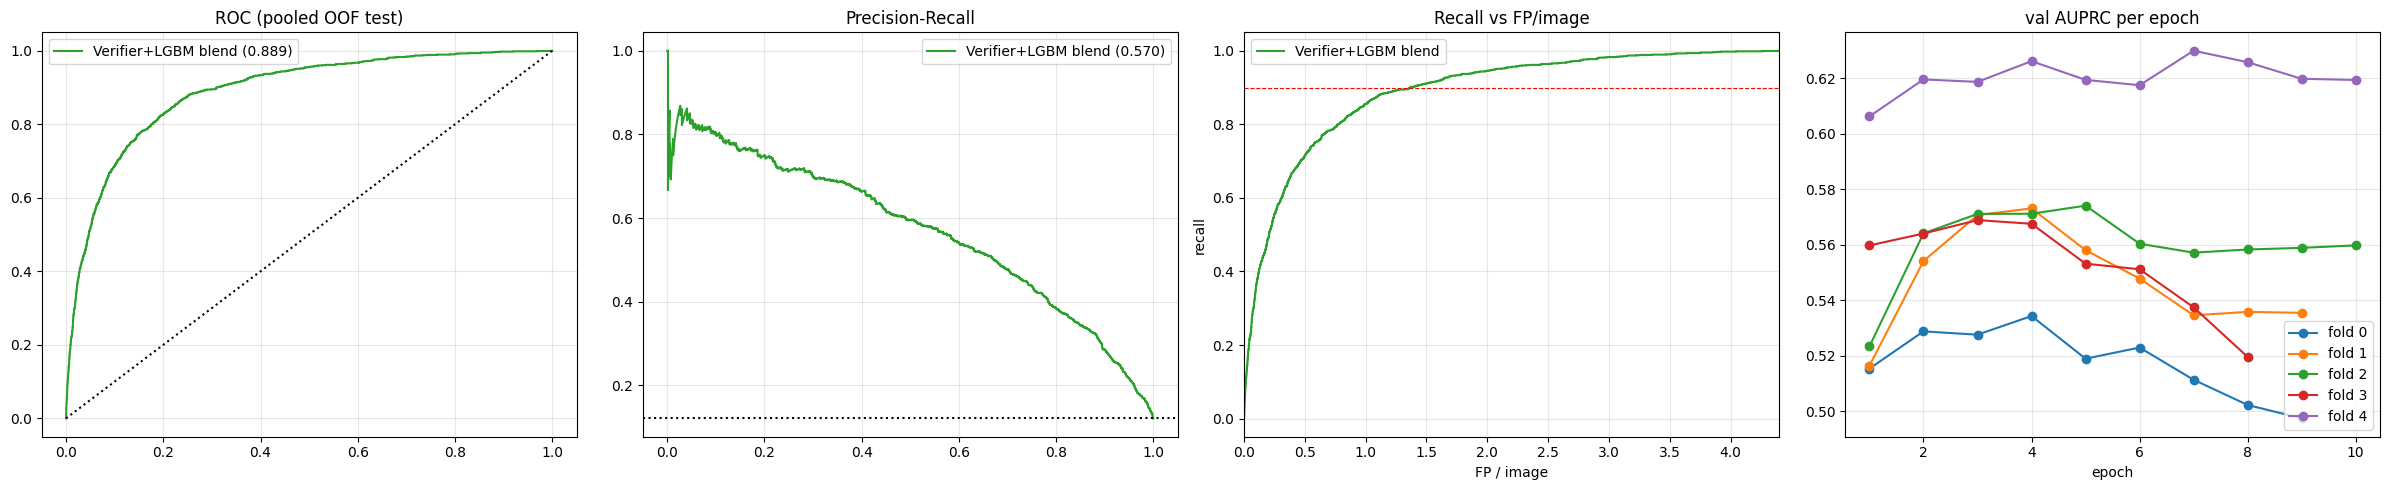

saved -> /kaggle/working/experiments/raddino_cv


In [13]:
def plot_results(blend, results, folds, n_patients, base_fp_img, target_recall, path):
    y, s = blend.y_test, blend.test_score
    label, color = "Verifier+LGBM blend", "tab:green"
    fig, ax = plt.subplots(1, 4, figsize=(24, 5))

    fpr, tpr, _ = roc_curve(y, s)
    ax[0].plot(fpr, tpr, color=color, label=f"{label} ({roc_auc_score(y, s):.3f})")
    ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title("ROC (pooled OOF test)")

    precision, recall, _ = precision_recall_curve(y, s)
    ax[1].plot(recall, precision, color=color, label=f"{label} ({average_precision_score(y, s):.3f})")
    ax[1].axhline(y.mean(), color="k", ls=":"); ax[1].set_title("Precision-Recall")

    order = np.argsort(-s)
    ax[2].plot(np.cumsum(1 - y[order]) / n_patients, np.cumsum(y[order]) / y.sum(), color=color, label=label)
    ax[2].axhline(target_recall, color="r", ls="--", lw=.8)
    ax[2].set_xlim(0, base_fp_img); ax[2].set_xlabel("FP / image"); ax[2].set_ylabel("recall"); ax[2].set_title("Recall vs FP/image")

    for k in folds:
        hist = results[k]["hist"]
        ax[3].plot(hist[:, 0], hist[:, 3], marker="o", label=f"fold {k}")
    ax[3].set_title("val AUPRC per epoch"); ax[3].set_xlabel("epoch")

    for a in ax:
        a.grid(alpha=.3); a.legend()
    plt.tight_layout(); plt.savefig(path, dpi=200); plt.show()


def save_outputs(data, blend, folds, pruning, tau, out_dir):
    out = data.df.iloc[blend.test_idx].copy()
    out["verifier_score"], out["blend_score"] = blend.verifier_test, blend.test_score
    out["fold"] = np.concatenate([[k] * len(results[k]["te"]) for k in folds])
    out.to_csv(os.path.join(out_dir, "oof_test_predictions.csv"), index=False)
    pruning.to_csv(os.path.join(out_dir, "pruning_summary.csv"), index=False)
    # everything needed to reproduce the final scoring rule on new data
    final = dict(score_head=blend.head, verifier_weight=blend.weight, tau=float(tau), **blend.norm_ref)
    with open(os.path.join(out_dir, "final_model_config.json"), "w") as f:
        json.dump(final, f, indent=2)
    print("saved ->", out_dir)


plot_results(blend, results, CFG.run_folds, n_patients, base_fp_img, CFG.target_recall, os.path.join(OUT_DIR, "cv_results.png"))
save_outputs(data, blend, CFG.run_folds, pruning, tau, OUT_DIR)